# **Лабораторна робота 7**
**Тема:** Проєктування функцій, робота з просторами імен та рекурсивні алгоритми.

**Мета:** Опанувати практичні навички процедурної та функціональної декомпозиції програмного коду мовою Python. Навчитися проектувати функції з адаптивними сигнатурами, використовуючи механізми пакування та розпакування позиційних (*args) та іменованих (**kwargs) аргументів, вивчити правила ізоляції та дозволу областей видимості змінних за моделлю LEGB. Опанувати синтаксис анонімних lambda-функцій для кастомного впорядкування складних інженерних колекцій у функціях вищого порядку (sorted, map, filter), а також розробити та дослідити рекурсивні алгоритми типу «розділяй і володарюй» із програмним контролем глибини системного стека викликів.


**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

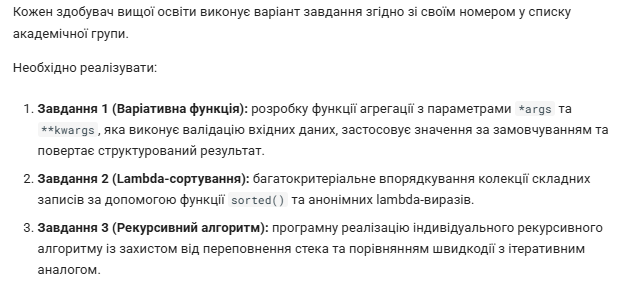

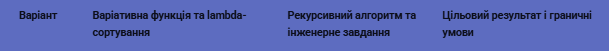
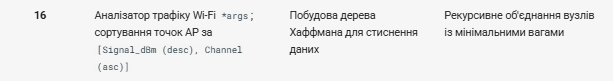

**ЗАВДАННЯ 1. Варіативна функція (`*args`, `**kwargs`): Аналізатор трафіку Wi-Fi**

In [1]:
def analyze_wifi_traffic(*frames: dict, **options) -> dict:
    min_signal_dbm: int | float = options.get("min_signal_dbm", -95)
    only_valid_channels: bool = options.get("only_valid_channels", True)
    allowed_channels: set[int] = set(options.get(
        "allowed_channels",
        {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 36, 40, 44, 48, 149, 153, 157, 161, 165}
    ))

    valid_records: list[dict] = []
    rejected_count = 0
    total_throughput_mbps = 0.0
    total_rssi_dbm = 0.0

    for idx, frame in enumerate(frames, start=1):
        if not isinstance(frame, dict):
            rejected_count += 1
            continue

        bssid = frame.get("bssid")
        ssid = frame.get("ssid")
        channel = frame.get("channel")
        signal_dbm = frame.get("signal_dbm")
        throughput_mbps = frame.get("throughput_mbps", 0.0)

        is_valid_bssid = isinstance(bssid, str) and len(bssid.strip()) > 0
        is_valid_ssid = isinstance(ssid, str) and len(ssid.strip()) > 0
        is_valid_channel = (
            isinstance(channel, int)
            and not isinstance(channel, bool)
            and (channel in allowed_channels if only_valid_channels else channel > 0)
        )
        is_valid_signal = (
            isinstance(signal_dbm, (int, float))
            and not isinstance(signal_dbm, bool)
            and -110 <= signal_dbm <= 0
            and signal_dbm >= min_signal_dbm
        )
        is_valid_throughput = (
            isinstance(throughput_mbps, (int, float))
            and not isinstance(throughput_mbps, bool)
            and throughput_mbps >= 0
        )

        if not (is_valid_bssid and is_valid_ssid and is_valid_channel and is_valid_signal and is_valid_throughput):
            rejected_count += 1
            continue

        record = {
            "id": idx,
            "bssid": bssid.strip().upper(),
            "ssid": ssid.strip(),
            "channel": channel,
            "signal_dbm": signal_dbm,
            "throughput_mbps": float(throughput_mbps)
        }
        valid_records.append(record)
        total_throughput_mbps += record["throughput_mbps"]
        total_rssi_dbm += record["signal_dbm"]

    count_valid = len(valid_records)
    avg_signal = round(total_rssi_dbm / count_valid, 2) if count_valid > 0 else None
    avg_throughput = round(total_throughput_mbps / count_valid, 2) if count_valid > 0 else 0.0

    result = {
        "total_frames_received": len(frames),
        "valid_frames_count": count_valid,
        "rejected_frames_count": rejected_count,
        "min_signal_filter_dbm": min_signal_dbm,
        "avg_signal_dbm": avg_signal,
        "total_throughput_mbps": round(total_throughput_mbps, 2),
        "avg_throughput_mbps": avg_throughput,
        "records": valid_records
    }

    print(f"{'АНАЛІЗАТОР ТРАФІКУ WI-FI (*args, **kwargs)':^78}")
    print("=" * 78)
    print(
        f"Отримано фреймів: {result['total_frames_received']} | "
        f"Валідних: {result['valid_frames_count']} | "
        f"Відхилено: {result['rejected_frames_count']}"
    )
    print(
        f"Поріг сигналу: {result['min_signal_filter_dbm']} dBm | "
        f"Сер. RSSI: {result['avg_signal_dbm']} dBm | "
        f"Сумарний трафік: {result['total_throughput_mbps']} Mbps"
    )
    print("-" * 78)
    print(f"{'BSSID':<19} | {'SSID':<18} | {'Ch':>4} | {'RSSI (dBm)':>11} | {'Mbps':>9}")
    print("-" * 78)
    for rec in result["records"]:
        print(
            f"{rec['bssid']:<19} | {rec['ssid']:<18} | {rec['channel']:>4d} | "
            f"{rec['signal_dbm']:>11d} | {rec['throughput_mbps']:>9.2f}"
        )
    print("=" * 78)

    return result


raw_wifi_frames = [
    {"bssid": "aa:bb:cc:11:22:01", "ssid": "Corp-5G-Main", "channel": 36, "signal_dbm": -48, "throughput_mbps": 412.5},
    {"bssid": "aa:bb:cc:11:22:02", "ssid": "Corp-24G-Office", "channel": 6, "signal_dbm": -54, "throughput_mbps": 96.0},
    {"bssid": "aa:bb:cc:11:22:03", "ssid": "Guest-Portal", "channel": 6, "signal_dbm": -67, "throughput_mbps": 34.2},
    {"bssid": "aa:bb:cc:11:22:04", "ssid": "Lab-Mesh-Node", "channel": 36, "signal_dbm": -48, "throughput_mbps": 285.8},
    {"bssid": "aa:bb:cc:11:22:05", "ssid": "IoT-Sensors", "channel": 11, "signal_dbm": -88, "throughput_mbps": 12.4},
    {"bssid": "aa:bb:cc:11:22:06", "ssid": "Weak-Edge-AP", "channel": 44, "signal_dbm": -92, "throughput_mbps": 8.0},
    {"bssid": "aa:bb:cc:11:22:99", "ssid": "Invalid-Ch-AP", "channel": 99, "signal_dbm": -50, "throughput_mbps": 120.0},
    {"bssid": "aa:bb:cc:11:22:00", "ssid": "Bad-Signal", "channel": 1, "signal_dbm": 15, "throughput_mbps": 50.0},
]

wifi_analysis = analyze_wifi_traffic(*raw_wifi_frames, min_signal_dbm=-85, only_valid_channels=True)

                  АНАЛІЗАТОР ТРАФІКУ WI-FI (*args, **kwargs)                  
Отримано фреймів: 8 | Валідних: 4 | Відхилено: 4
Поріг сигналу: -85 dBm | Сер. RSSI: -54.25 dBm | Сумарний трафік: 828.5 Mbps
------------------------------------------------------------------------------
BSSID               | SSID               |   Ch |  RSSI (dBm) |      Mbps
------------------------------------------------------------------------------
AA:BB:CC:11:22:01   | Corp-5G-Main       |   36 |         -48 |    412.50
AA:BB:CC:11:22:02   | Corp-24G-Office    |    6 |         -54 |     96.00
AA:BB:CC:11:22:03   | Guest-Portal       |    6 |         -67 |     34.20
AA:BB:CC:11:22:04   | Lab-Mesh-Node      |   36 |         -48 |    285.80


**ЗАВДАННЯ 2. Lambda-сортування точок доступу Wi-Fi за [Signal_dBm (desc), Channel (asc)]**

In [2]:
access_points = [
    {"bssid": "AA:BB:CC:11:22:01", "ssid": "Corp-5G-Main", "signal_dbm": -48, "channel": 36, "clients": 28},
    {"bssid": "AA:BB:CC:11:22:04", "ssid": "Lab-Mesh-Node", "signal_dbm": -48, "channel": 36, "clients": 14},
    {"bssid": "AA:BB:CC:11:22:07", "ssid": "Floor2-5G-East", "signal_dbm": -48, "channel": 48, "clients": 19},
    {"bssid": "AA:BB:CC:11:22:02", "ssid": "Corp-24G-Office", "signal_dbm": -54, "channel": 6, "clients": 22},
    {"bssid": "AA:BB:CC:11:22:08", "ssid": "Floor1-24G-West", "signal_dbm": -54, "channel": 1, "clients": 11},
    {"bssid": "AA:BB:CC:11:22:03", "ssid": "Guest-Portal", "signal_dbm": -67, "channel": 6, "clients": 35},
    {"bssid": "AA:BB:CC:11:22:05", "ssid": "IoT-Sensors", "signal_dbm": -74, "channel": 11, "clients": 42},
]

sorted_aps = sorted(
    access_points,
    key=lambda ap: (-ap["signal_dbm"], ap["channel"])
)

print(f"{'СОРТУВАННЯ ТОЧОК ДОСТУПУ WI-FI: Signal_dBm (DESC), Channel (ASC)':^78}")
print("=" * 78)
print(f"{'Rank':<5} | {'BSSID':<19} | {'SSID':<18} | {'Signal (dBm)':>12} | {'Channel':>8} | {'Clients':>7}")
print("-" * 78)
for rank, ap in enumerate(sorted_aps, start=1):
    print(
        f"{rank:<5d} | {ap['bssid']:<19} | {ap['ssid']:<18} | "
        f"{ap['signal_dbm']:>12d} | {ap['channel']:>8d} | {ap['clients']:>7d}"
    )
print("=" * 78)

       СОРТУВАННЯ ТОЧОК ДОСТУПУ WI-FI: Signal_dBm (DESC), Channel (ASC)       
Rank  | BSSID               | SSID               | Signal (dBm) |  Channel | Clients
------------------------------------------------------------------------------
1     | AA:BB:CC:11:22:01   | Corp-5G-Main       |          -48 |       36 |      28
2     | AA:BB:CC:11:22:04   | Lab-Mesh-Node      |          -48 |       36 |      14
3     | AA:BB:CC:11:22:07   | Floor2-5G-East     |          -48 |       48 |      19
4     | AA:BB:CC:11:22:08   | Floor1-24G-West    |          -54 |        1 |      11
5     | AA:BB:CC:11:22:02   | Corp-24G-Office    |          -54 |        6 |      22
6     | AA:BB:CC:11:22:03   | Guest-Portal       |          -67 |        6 |      35
7     | AA:BB:CC:11:22:05   | IoT-Sensors        |          -74 |       11 |      42


**ЗАВДАННЯ 3. Рекурсивний алгоритм побудови дерева Хаффмана із контролем стека та порівнянням з ітеративним аналогом**

In [3]:
import heapq
import sys
import time


def _make_node(weight: int, symbol: str | None = None, left: tuple | None = None, right: tuple | None = None) -> tuple:
    # Вузол подається кортежем: (weight, symbol, left, right) без використання ООП-класів
    return (weight, symbol, left, right)


def _node_sort_key(node: tuple) -> tuple[int, str]:
    weight, symbol, _, _ = node
    return (weight, symbol if symbol is not None else "~")


def build_huffman_tree_recursive(
    freq_map: dict[str, int],
    depth: int = 0,
    max_allowed_depth: int | None = None,
    _heap: list[tuple[tuple[int, str], int, tuple]] | None = None,
    _seq: int = 0
) -> tuple:
    if max_allowed_depth is None:
        max_allowed_depth = min(sys.getrecursionlimit() - 50, max(64, len(freq_map) * 4 + 16))
    if depth > max_allowed_depth:
        raise RecursionError(
            f"Перевищено ліміт глибини рекурсії: depth={depth} > max_allowed_depth={max_allowed_depth}"
        )

    if not freq_map:
        raise ValueError("Словник частот символів не може бути порожнім.")

    if _heap is None:
        _heap = []
        for sym, w in sorted(freq_map.items()):
            _seq += 1
            node = _make_node(weight=w, symbol=sym)
            heapq.heappush(_heap, (_node_sort_key(node), _seq, node))

    if len(_heap) == 1:
        return _heap[0][2]

    _, _, left_node = heapq.heappop(_heap)
    _, _, right_node = heapq.heappop(_heap)
    merged_node = _make_node(weight=left_node[0] + right_node[0], symbol=None, left=left_node, right=right_node)

    _seq += 1
    heapq.heappush(_heap, (_node_sort_key(merged_node), _seq, merged_node))

    return build_huffman_tree_recursive(
        freq_map=freq_map,
        depth=depth + 1,
        max_allowed_depth=max_allowed_depth,
        _heap=_heap,
        _seq=_seq
    )


def build_huffman_tree_iterative(freq_map: dict[str, int]) -> tuple:
    if not freq_map:
        raise ValueError("Словник частот символів не може бути порожнім.")

    heap: list[tuple[tuple[int, str], int, tuple]] = []
    seq = 0
    for sym, w in sorted(freq_map.items()):
        seq += 1
        node = _make_node(weight=w, symbol=sym)
        heapq.heappush(heap, (_node_sort_key(node), seq, node))

    while len(heap) > 1:
        _, _, left_node = heapq.heappop(heap)
        _, _, right_node = heapq.heappop(heap)
        merged_node = _make_node(weight=left_node[0] + right_node[0], symbol=None, left=left_node, right=right_node)
        seq += 1
        heapq.heappush(heap, (_node_sort_key(merged_node), seq, merged_node))

    return heap[0][2]


def generate_huffman_codes_recursive(node: tuple | None, prefix: str = "", codes: dict[str, str] | None = None) -> dict[str, str]:
    if codes is None:
        codes = {}
    if node is None:
        return codes
    _, symbol, left, right = node
    if symbol is not None:
        codes[symbol] = prefix if prefix else "0"
        return codes
    generate_huffman_codes_recursive(left, prefix + "0", codes)
    generate_huffman_codes_recursive(right, prefix + "1", codes)
    return codes


symbol_frequencies = {
    "ACK": 45,
    "DATA": 32,
    "BEACON": 18,
    "PROBE": 12,
    "AUTH": 9,
    "DEAUTH": 4,
    "QOS": 15,
    "CTRL": 7
}

safe_depth_limit = 64
rec_root = build_huffman_tree_recursive(symbol_frequencies, depth=0, max_allowed_depth=safe_depth_limit)
iter_root = build_huffman_tree_iterative(symbol_frequencies)
huffman_codes = generate_huffman_codes_recursive(rec_root)

benchmark_freqs = {f"SYM_{i:02d}": (i * 7 + 3) % 97 + 1 for i in range(1, 41)}
iterations = 500

t0 = time.perf_counter()
for _ in range(iterations):
    build_huffman_tree_recursive(benchmark_freqs, depth=0, max_allowed_depth=120)
rec_elapsed_ms = (time.perf_counter() - t0) * 1000.0

t1 = time.perf_counter()
for _ in range(iterations):
    build_huffman_tree_iterative(benchmark_freqs)
iter_elapsed_ms = (time.perf_counter() - t1) * 1000.0

title_huffman = "ДЕРЕВО ХАФФМАНА: РЕКУРСИВНЕ ОБ'ЄДНАННЯ ВУЗЛІВ З МІНІМАЛЬНИМИ ВАГАМИ"
title_bench = f"ПОРІВНЯННЯ ШВИДКОДІЇ ({iterations} ітерацій, {len(benchmark_freqs)} символів)"

print(f"{title_huffman:^78}")
print("=" * 78)
print(
    f"Корінь дерева вага: {rec_root[0]} (ітеративно: {iter_root[0]}) | "
    f"Ліміт рекурсії: {safe_depth_limit} | sys.getrecursionlimit(): {sys.getrecursionlimit()}"
)
print("-" * 78)
print(f"{'Symbol':<10} | {'Weight':>8} | {'Code':<12} | {'Code Len':>8}")
print("-" * 78)
for sym in sorted(symbol_frequencies.keys()):
    code = huffman_codes[sym]
    print(f"{sym:<10} | {symbol_frequencies[sym]:>8d} | {code:<12} | {len(code):>8d}")
print("-" * 78)
print(f"{title_bench:^78}")
print("-" * 78)
print(f"Рекурсивний варіант : {rec_elapsed_ms:>8.3f} мс ({rec_elapsed_ms / iterations:.5f} мс / виклик)")
print(f"Ітеративний варіант : {iter_elapsed_ms:>8.3f} мс ({iter_elapsed_ms / iterations:.5f} мс / виклик)")
print(f"Відношення (Rec/Iter): {rec_elapsed_ms / iter_elapsed_ms:>8.2f}x")
print("=" * 78)

     ДЕРЕВО ХАФФМАНА: РЕКУРСИВНЕ ОБ'ЄДНАННЯ ВУЗЛІВ З МІНІМАЛЬНИМИ ВАГАМИ      
Корінь дерева вага: 142 (ітеративно: 142) | Ліміт рекурсії: 64 | sys.getrecursionlimit(): 1000
------------------------------------------------------------------------------
Symbol     |   Weight | Code         | Code Len
------------------------------------------------------------------------------
ACK        |       45 | 11           |        2
AUTH       |        9 | 1010         |        4
BEACON     |       18 | 100          |        3
CTRL       |        7 | 10111        |        5
DATA       |       32 | 01           |        2
DEAUTH     |        4 | 10110        |        5
PROBE      |       12 | 000          |        3
QOS        |       15 | 001          |        3
------------------------------------------------------------------------------
               ПОРІВНЯННЯ ШВИДКОДІЇ (500 ітерацій, 40 символів)               
------------------------------------------------------------------------------

**Висновки**

1. **Просторові витрати рекурсії:** Кожен рекурсивний виклик створює новий стековий кадр у пам'яті ($O(d)$ за глибиною), тому надмірна глибина веде до `RecursionError`. Контроль глибини захищає програму від переповнення стека.
2. **Рекурсія проти ітерації:** Обидва підходи до побудови дерева Хаффмана з купою (`heapq`) мають час $O(n \log n)$, але ітеративний цикл працює в одному кадрі й не витрачає пам'ять на додаткові рекурсивні виклики.
3. **Роль `lambda`:** `lambda` дозволяє коротко задавати ключі сортування (`sorted(..., key=lambda ...)`) без зайвих іменованих функцій, що спрощує функціональну декомпозицію.

**Контрольні питання**

1. Як влаштовано механізм передачі параметрів pass-by-object-reference у CPython? Чому спроба змінити значення цілочисельного аргументу всередині функції не впливає на вихідну змінну, а зміна списку через метод append() мутує вихідний об'єкт?

Передається посилання на об'єкт (pass-by-object-reference). Незмінний `int` при переприсвоєнні створює новий об'єкт і не змінює зовнішню змінну, а змінюваний `list` через `append()` змінюється на місці (in-place).

2. Опишіть послідовність пошуку ідентифікаторів згідно з правилом LEGB. За яких умов інтерпретатор генерує виняток UnboundLocalError при зверненні до змінної всередині функції?

Пошук імен іде за схемою: **L**ocal $ightarrow$ **E**nclosing $ightarrow$ **G**lobal $ightarrow$ **B**uilt-in. `UnboundLocalError` виникає, коли змінну читають до присвоєння в тій самій функції, де вона вважається локальною (через присвоєння без `global` або `nonlocal`).

3. У чому полягає різниця між операторами *args та **kwargs у сигнатурі функції? До яких типів даних CPython перетворює передані аргументи під час пакування?

`*args` збирає зайві позиційні аргументи в `tuple`, а `**kwargs` — зайві іменовані аргументи в `dict`.

4. Розкрийте системний механізм функціонування lambda-виразів у Python. Які синтаксичні та функціональні обмеження накладаються на lambda-функції порівняно зі стандартними функціями def?

`lambda` створює анонімну функцію з одним виразом, який повертається автоматично без `return`. Вона не підтримує інструкції (`if`/`for`/присвоєння як стейтменти), кілька рядків і `docstring`.

5. Чому при глибокій рекурсії виникає виняток RecursionError? Які функції модуля sys дозволяють інспектувати та програмно модифікувати ліміт глибини стекових кадрів?

`RecursionError` виникає при досягненні ліміту глибини стека викликів. Перевірити ліміт можна через `sys.getrecursionlimit()`, змінити — через `sys.setrecursionlimit()`.

6. Сформулюйте сутність теореми Master Theorem для оцінки складності рекурсивних алгоритмів «розділяй і володарюй». Якою є асимптотична складність алгоритму QuickSort у найкращому, середньому та найгіршому випадках?

Master Theorem оцінює складність рекурентностей $T(n) = aT(n/b) + f(n)$ порівнянням $f(n)$ із $n^{\log_b a}$. Для **QuickSort** складність становить: найкращий — $\Theta(n \log n)$, середній — $\Theta(n \log n)$, найгірший — $\Theta(n^2)$.